# H&M 상품 및 고객 분석
상품 105,542개와 거래 원본 첫 분할에서 고객 ID를 기준으로 고정 추출한 약 1% 표본을 분석한다. 관찰 기간은 2018-09-20부터 2019-01-04까지이며, 해당 분할 이외의 구매는 포함하지 않는다. 가격은 원본의 정규화 값으로 통화 금액으로 해석하지 않는다. 이미지 40장은 제한된 예시다.

In [1]:
# 라이브러리와 분석 클래스를 불러온다.
from pathlib import Path
import sys
import numpy as 넘파이
import pandas as 판다스
import matplotlib.pyplot as 그래프
import matplotlib.image as 이미지읽기
import seaborn as 시본
프로젝트경로 = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(프로젝트경로 / 'src'))
from pipeline import DataAnalyzer as 데이터분석기
판다스.set_option('display.max_columns', 12)

## 데이터 불러오기와 기본 탐색

In [2]:
# 상품 데이터와 거래 표본을 읽는다.
상품분석기 = 데이터분석기(프로젝트경로 / 'data/raw/hm/articles.csv')
상품표 = 상품분석기.데이터불러오기()
거래표 = 판다스.read_csv(프로젝트경로 / 'data/raw/hm/transactions_customer_sample.csv')
상품표['article_id'] = 상품표['article_id'].astype(str).str.zfill(10)
거래표['article_id'] = 거래표['article_id'].astype(str).str.zfill(10)
거래표['t_dat'] = 판다스.to_datetime(거래표['t_dat'])
print('상품 행·열:', 상품표.shape, '거래 행·열:', 거래표.shape)
상품표.head()

상품 행·열: (105542, 25) 거래 행·열: (45374, 5)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,...,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,108775,Strap top,253,Vest top,Garment Upper body,...,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,108775,Strap top,253,Vest top,Garment Upper body,...,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,108775,Strap top (1),253,Vest top,Garment Upper body,...,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,...,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,...,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [3]:
상품표.info()
상품표.describe(include='all').T.head(8)

<class 'pandas.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   article_id                    105542 non-null  str  
 1   product_code                  105542 non-null  int64
 2   prod_name                     105542 non-null  str  
 3   product_type_no               105542 non-null  int64
 4   product_type_name             105542 non-null  str  
 5   product_group_name            105542 non-null  str  
 6   graphical_appearance_no       105542 non-null  int64
 7   graphical_appearance_name     105542 non-null  str  
 8   colour_group_code             105542 non-null  int64
 9   colour_group_name             105542 non-null  str  
 10  perceived_colour_value_id     105542 non-null  int64
 11  perceived_colour_value_name   105542 non-null  str  
 12  perceived_colour_master_id    105542 non-null  int64
 13  perceived_colour_master_n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
article_id,105542,105542,0108775015,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_code,105542.0,NaN,NaN,NaN,698424.563378,128462.384432,108775.0,616992.5,702213.0,796703.0,959461.0
prod_name,105542,45875,Dragonfly dress,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_type_no,105542.0,NaN,NaN,NaN,234.861875,75.049308,-1.0,252.0,259.0,272.0,762.0
product_type_name,105542,131,Trousers,11169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_group_name,105542,19,Garment Upper body,42741,NaN,NaN,NaN,NaN,NaN,NaN,NaN
graphical_appearance_no,105542.0,NaN,NaN,NaN,1009515.075723,22413.585778,-1.0,1010008.0,1010016.0,1010016.0,1010029.0
graphical_appearance_name,105542,30,Solid,49747,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**해석:** 상품표는 105,542행·25열이고 거래 표본은 45,374행이다. 판매 기록의 상품 ID를 기준으로 연결할 수 있으므로 상품 속성과 구매 기록을 함께 분석할 수 있다.

## 결측치와 그룹별 중앙값

In [4]:
# 실제로 결측이 있는 상품 설명의 길이를 계산한다.
상품분석기.텍스트특성추가('prod_name')
상품표['description_length'] = 상품표['detail_desc'].str.len()
전_결측 = 상품표['description_length'].isna().sum()
상품분석기.결측치처리('description_length', 'product_group_name', 출력열='description_length_filled')
후_결측 = 상품표['description_length_filled'].isna().sum()
print('상품 설명 길이 결측 전:', 전_결측, '후:', 후_결측, '대치 수:', 전_결측-후_결측)
상품표.loc[상품표['description_length'].isna(), ['prod_name','product_group_name','description_length','description_length_filled']].head()

상품 설명 길이 결측 전: 416 후: 0 대치 수: 416


,prod_name,product_group_name,description_length,description_length_filled
1467,Marshall Lace up Top,Garment Upper body,NaN,132.0
2644,OL TAGE PQ,Shoes,NaN,142.5
2645,OL TAGE PQ,Shoes,NaN,142.5
2742,Ellen Shortie Daisy Low 3p,Underwear,NaN,127.0
2743,Ellen Shortie Daisy Low 3p,Underwear,NaN,127.0


**해석:** 상품 설명 길이 결측 416개를 상품군별 중앙값으로 대치한 결과 남은 결측은 0개다. 설명이 누락된 상품도 길이를 사용하는 분석에 포함할 수 있지만, 대치한 값은 실제 설명의 길이가 아니므로 결과 해석에 주의한다.

## NumPy 이미지 피처

In [5]:
# 동일한 크기로 다운샘플링한 이미지별 통계를 벡터 연산한다.
이미지경로들 = sorted((프로젝트경로/'data/raw/hm/images').rglob('*.jpg'))
이미지들 = 넘파이.stack([이미지읽기.imread(경로)[::20, ::20, :3][:20, :20, :] for 경로 in 이미지경로들])
평균들, 표준편차들 = 데이터분석기.이미지특성계산(이미지들)
이미지표 = 판다스.DataFrame({'article_id':[경로.stem for 경로 in 이미지경로들], 'image_mean':평균들, 'image_std':표준편차들})
상품표 = 상품표.merge(이미지표, on='article_id', how='left', validate='one_to_one')
print('배열 모양:', 이미지들.shape, '피처가 연결된 상품:', 상품표['image_mean'].notna().sum())
상품표.loc[상품표['image_mean'].notna(), ['article_id','prod_name','image_mean','image_std']].head()

배열 모양: (40, 20, 20, 3) 피처가 연결된 상품: 40


,article_id,prod_name,image_mean,image_std
0,0108775015,Strap top,224.905000,40.778744
1,0108775044,Strap top,233.646667,3.709468
2,0108775051,Strap top (1),232.547500,9.539536
3,0110065001,OP T-shirt (Idro),230.660833,14.031719
4,0110065002,OP T-shirt (Idro),231.343333,2.637004


**해석:** 확보한 이미지 40장 모두 상품 ID에 연결됐다. 각 사진에서 공통 크기로 잘라낸 20×20×3 배열의 픽셀 평균과 표준편차를 상품 열로 추가했으며, 이 통계는 해당 영역의 밝기 분포를 요약한다.

## 거래와 상품 연결, IQR

In [6]:
# 구매 거래를 상품 ID로 연결한다.
분석표 = 거래표.merge(상품표, on='article_id', how='left', validate='many_to_one')
print('거래 행:',len(분석표), '고객 수:', 분석표.customer_id.nunique(), '상품 미연결:', 분석표['prod_name'].isna().sum())
분석기 = 데이터분석기('unused.csv'); 분석기.데이터표 = 분석표
이상치결과 = 분석기.이상치탐지('price')
print('Q1:',이상치결과['q1'],'Q3:',이상치결과['q3'],'IQR:',이상치결과['iqr'],'상한:',이상치결과['upper'],'후보:',이상치결과['mask'].sum())
print(분석표[['price','name_length','description_length_filled']].describe())
상관행렬 = 분석표[['price','name_length','description_length_filled']].corr()
print('가격-상품명 길이:',상관행렬.loc['price','name_length'])
print('가격-상품 설명 길이:',상관행렬.loc['price','description_length_filled'])

거래 행: 45374 고객 수: 5932 상품 미연결: 0
Q1: 0.0152372881355932 Q3: 0.0338813559322033 IQR: 0.018644067796610105 상한: 0.06184745762711846 후보: 2893
              price   name_length  description_length_filled
count  45374.000000  45374.000000               45374.000000
mean       0.029416     14.565566                 126.283433
std        0.022868      6.055442                  54.851200
min        0.000831      1.000000                  11.000000
25%        0.015237     10.000000                  88.000000
50%        0.025407     14.000000                 120.000000
75%        0.033881     19.000000                 156.000000
max        0.506780     30.000000                 528.000000
가격-상품명 길이: -0.06402859218632151
가격-상품 설명 길이: 0.35591433490515306


**해석:** 가격의 평균은 0.029416, 중앙값은 0.025407, 표준편차는 0.022868이다. Q1은 0.015237, Q3는 0.033881이다. 평균이 중앙값보다 높고 IQR 경계 밖 거래는 2,893건(6.38%)이므로 비싼 값들이 분포의 오른쪽 꼬리를 늘릴 수 있다. 가격과 상품명 길이의 상관계수는 -0.064로 매우 약하고, 가격과 상품 설명 길이는 0.356으로 양의 관계가 관찰된다. 상품군이나 대치값 등의 영향을 통제하지 않았으므로 인과관계로 해석하지 않는다.

## 시각화 6종

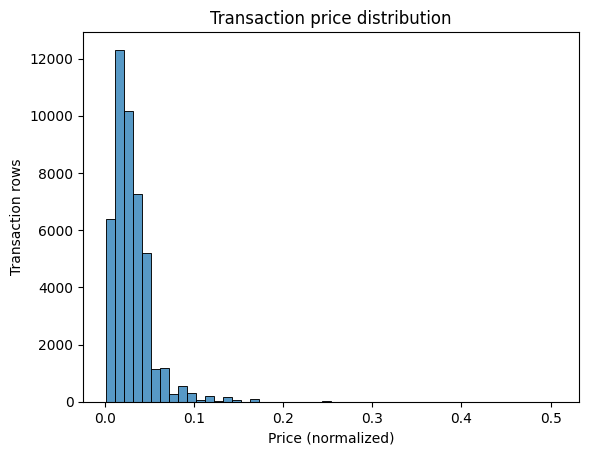

In [7]:
# 히스토그램: 가격 분포
시본.histplot(분석표['price'], bins=50); 그래프.title('Transaction price distribution'); 그래프.xlabel('Price (normalized)'); 그래프.ylabel('Transaction rows'); 그래프.show()

**해석:** 45,374건의 가격 분포를 보면 값이 낮은 구간에 관측치가 많다. 평균과 중앙값 차이와 함께 오른쪽 꼬리의 영향을 살펴볼 수 있다.

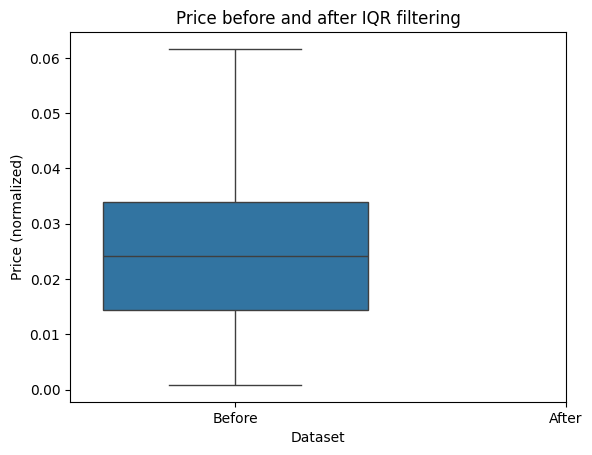

In [8]:
# 박스플롯: IQR 후보 제외 전후
시본.boxplot(data=[분석표['price'].dropna(),분석표.loc[~이상치결과['mask'],'price'].dropna()]); 그래프.xticks([0,1],['Before','After']); 그래프.title('Price before and after IQR filtering'); 그래프.xlabel('Dataset'); 그래프.ylabel('Price (normalized)'); 그래프.show()

**해석:** IQR 1.5배 기준 경계 밖인 2,893건을 제외하면 가격 분포의 상단 범위가 줄어든다. 이 값들이 실제 고가 상품일 수 있으므로 원본에서 삭제하지 않고 비교에만 사용했다.

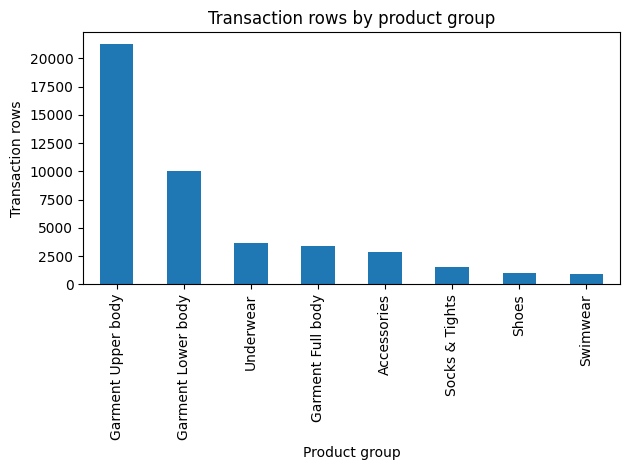

In [9]:
# 막대그래프: 상품군별 거래 수
개수=분석표['product_group_name'].value_counts().head(8); 개수.plot.bar(); 그래프.title('Transaction rows by product group'); 그래프.xlabel('Product group'); 그래프.ylabel('Transaction rows'); 그래프.tight_layout(); 그래프.show()

**해석:** 상품군별 거래 수는 같은 고객의 여러 구매 항목을 포함한 45,374행을 기준으로 한다. 거래 행이 많은 상품군을 재고·상품 구성 검토 대상으로 삼을 수 있지만, 고객 수나 주문 건수와 같지는 않다.

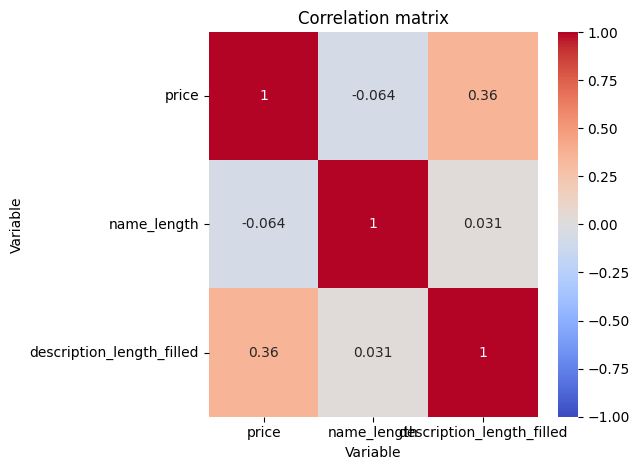

In [10]:
# 연속형 변수 세 개의 상관관계를 시각화한다.
시본.heatmap(상관행렬, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
그래프.title('Correlation matrix'); 그래프.xlabel('Variable'); 그래프.ylabel('Variable'); 그래프.tight_layout(); 그래프.show()

**해석:** 가격과 설명 길이의 상관계수는 0.356이고 가격과 상품명 길이는 -0.064다. 설명 길이의 관계가 더 뚜렷하지만 상품 종류가 함께 영향을 줄 수 있어 인과관계는 추가 검증해야 한다.

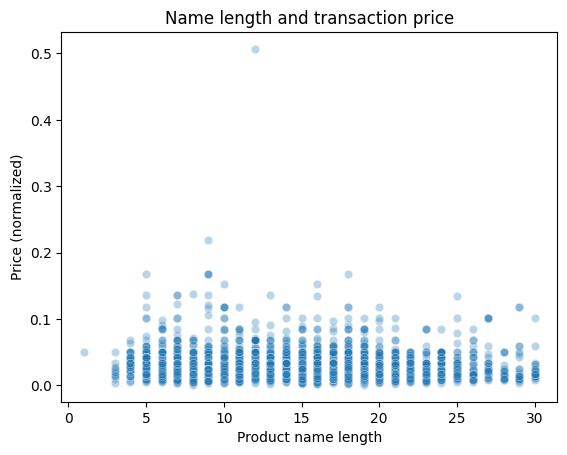

In [11]:
# 산점도: 이름 길이와 가격
시본.scatterplot(data=분석표.sample(min(3000,len(분석표)),random_state=42),x='name_length',y='price',alpha=.3); 그래프.title('Name length and transaction price'); 그래프.xlabel('Product name length'); 그래프.ylabel('Price (normalized)'); 그래프.show()

**해석:** 산점도는 45,374행 중 무작위 3,000행을 보여준다. 가격과 상품명 길이의 전체 상관계수는 -0.064이므로, 상품명 길이만으로 가격을 예측하기는 어렵다.

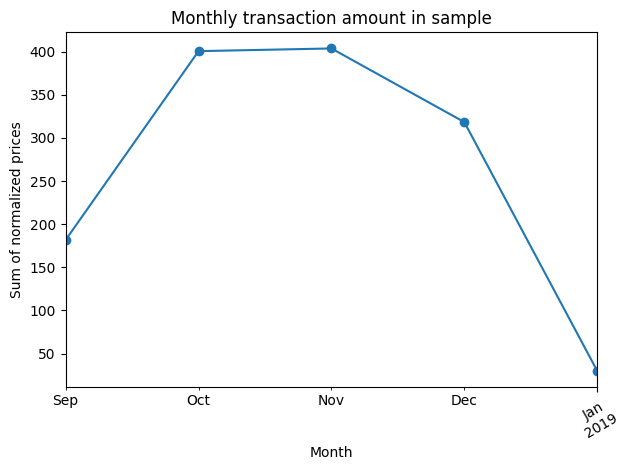

In [12]:
# 월별 합계는 정규화된 가격의 합이다.
월별합계 = 분석표.set_index('t_dat')['price'].resample('MS').sum()
월별합계.plot(marker='o'); 그래프.title('Monthly transaction amount in sample'); 그래프.xlabel('Month'); 그래프.ylabel('Sum of normalized prices'); 그래프.xticks(rotation=30); 그래프.tight_layout(); 그래프.show()

**해석:** 월별 추이는 관찰기간 내 거래 45,374행의 정규화 가격 합계다. 첫 달과 마지막 달은 관찰 기간이 일부뿐이므로 완전한 달과 직접 비교하기 어렵다.

## RFM 고객 세분화

In [13]:
# 주문번호가 없어 구매일 수를 빈도 대용치로 사용한다.
분석표['purchase_day'] = 분석표['t_dat']
고객지표=분석기.RFM계산('customer_id','t_dat','price','purchase_day')
# 최근성의 낮은 값과 빈도·금액의 높은 값이 높은 점수다. 같은 값은 같은 점수를 받는다.
for 열이름 in ['recency','frequency','monetary']:
    순위=고객지표[열이름].rank(method='average',pct=True,ascending=(열이름!='recency'))
    고객지표[열이름+'_score']=넘파이.ceil(순위*4).clip(1,4).astype(int)
# 우선순위를 명시해 한 고객을 한 그룹에만 배정한다.
고객지표['segment']=넘파이.select([(고객지표.recency_score>=3)&(고객지표.frequency_score>=3)&(고객지표.monetary_score>=3), (고객지표.recency_score>=3)&(고객지표.frequency==1), (고객지표.recency_score<=2), (고객지표.frequency_score>=3)],['VIP','Recent one-day','Older activity','Repeat'],default='Other')
요약표=고객지표.groupby('segment').agg(customers=('customer_id','size'),mean_recency=('recency','mean'),mean_days=('frequency','mean'),mean_monetary=('monetary','mean'))
print('기준일:',분석표.t_dat.max(),'고객:',len(고객지표)); print(요약표); 고객지표.head()

기준일: 2019-01-04 00:00:00 고객: 5932
                customers  mean_recency  mean_days  mean_monetary
segment                                                          
Older activity       2963     67.438407   1.543706       0.154766
Recent one-day        890     19.774157   1.000000       0.083961
Repeat                432     16.837963   2.442130       0.084873
VIP                  1647     15.633273   4.497268       0.464347


,customer_id,last_order,frequency,monetary,recency,recency_score,frequency_score,monetary_score,segment
0,000fb6e772c5d0023892065e659963da90b1866035558e...,2019-01-04,20,1.775458,0,4,4,4,VIP
1,001e7e640da3c0a2ae3c1444d9fba300646d050e7ba601...,2019-01-03,2,0.376102,1,4,3,4,VIP
2,0027ec4b82481e65d455c327647048c1b6ed9148daea1e...,2019-01-04,1,0.076271,0,4,1,2,Recent one-day
3,00299609d2f3cd490b2e5939f22c881340ece8a1dd3d63...,2018-09-23,1,0.025407,103,1,1,1,Older activity
4,002e0b61a6fbc3425d76f3f222750f60165d44e2572267...,2018-11-23,2,0.102966,42,2,3,2,Older activity


**해석:** 관찰 고객 5,932명 중 VIP 규칙에 해당하는 고객은 1,647명(27.76%)이며 평균 구매일은 4.50일이다. Older activity는 2,963명(49.95%)이고 평균 최근성은 67.44일이다. Recent one-day는 890명(15.00%), Repeat은 432명이다. 이는 관찰 기간 내 분류이며 실제 신규 가입이나 이탈을 확정하지 않는다.

## 해석과 제한
- 표본은 2018-09-20~2019-01-04의 첫 번째 거래 분할에서 고객 단위로 선택했다. 이 기간 밖의 구매를 포함하지 않으므로 신규 가입이나 실제 이탈을 확정할 수 없다.
- 주문번호가 없어 Frequency는 관찰 기간의 고유 구매일 수로 계산한다. 판매 채널에는 오프라인도 포함된다.
- 가격은 원본의 상대적 정규화 값이며 통화·실제 매출액이라고 단정하지 않는다.
- 이미지 40장은 모든 상품을 대표하지 않는다. 공통 영역을 슬라이싱했으므로 이미지 전체의 평균과는 다르다.
- 결측된 설명 길이는 관측한 실제값이 아니라 상품군 중앙값 추정치다. 상관관계는 인과관계를 뜻하지 않는다.